# Deep Learning DLY0100 - Parcial 2
## Clasificación de personajes de Los Simpson con CNN

Antonio Jara, Florencia Soto

El objetivo es construir, comparar y evaluar redes neuronales convolucionales para reconocer 18 personajes de Los Simpson. Se adaptaron las dos arquitecturas del laboratorio **2.2.3 Redes Convolucionales**.

Se comparan seis configuraciones con tres semillas cada una, dando un total de 18 entrenamientos (RUN).

## 1. Entorno y herramientas

El cuaderno fue pensado para ser usado en un entorno de Google Colab. Selecciona **Ejecutar todo**. La primera celda descarga `utilidades.py`, el cual contiene todas las funciones utilizadas en este cuaderno, desde el [repositorio del proyecto](https://github.com/antoniojarasanchez/dly0100-cnn-simpsons) si no está en la carpeta de trabajo, y luego importa sus funciones.

El dataset se descargará y extraerá automáticamente desde Google Drive.

Los 18 RUN se ejecutan sin cambiar parámetros manualmente. TensorFlow/Keras construye y entrena las CNN, OpenCV carga las imágenes, scikit-learn permite dividir datos y calcular métricas, y Matplotlib muestra los resultados.

Se adaptan las arquitecturas y los pasos del laboratorio a imágenes de 64 × 64 y 18 clases correspondientes a los personajes con más imágenes en el dataset.

Las semillas controlan la inicialización y el barajado de las imágenes, lo que favorece la reproducibilidad, pero no garantiza resultados 100% iguales en distintas ejecuciones.


In [ ]:
import subprocess
import sys
from pathlib import Path
from urllib.request import urlopen

import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from sklearn.model_selection import train_test_split
from tensorflow import keras
from tensorflow.keras.layers import Flatten

try:
    import gdown
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "gdown"])
    import gdown

IMG_SIZE = 64
SEMILLA_PARTICION = 2026
SEMILLAS = [42, 123, 456]
SEMILLA_PRINCIPAL = 42
BATCH_SIZE = 64
MAX_EPOCHS = 40
PACIENCIA = 8
DATASET_DIR = Path("data")
RESULTADOS_DIR = Path("resultados")
FIGURAS_DIR = RESULTADOS_DIR / "figuras"
PESOS_DIR = Path("pesos")
DATASET_DIR.mkdir(exist_ok=True)
RESULTADOS_DIR.mkdir(exist_ok=True)
FIGURAS_DIR.mkdir(exist_ok=True)
PESOS_DIR.mkdir(exist_ok=True)


URL_UTILIDADES = (
    "https://raw.githubusercontent.com/antoniojarasanchez/"
    "dly0100-cnn-simpsons/main/utilidades.py"
)

# Conserva el módulo local si ya está en la carpeta de trabajo.
if not Path("utilidades.py").is_file():
    print("Descargando utilidades.py desde GitHub", flush=True)
    with urlopen(URL_UTILIDADES, timeout=30) as respuesta:
        Path("utilidades.py").write_bytes(respuesta.read())

from utilidades import (
    cargar_datos, crear_modelo, elegir_configuracion,
    empaquetar_resultados, entrenar_configuraciones, evaluar_configuracion,
    graficar_comparacion, graficar_historial, graficar_matriz,
    guardar_respaldo, mostrar_distribucion, mostrar_ejemplos, mostrar_tabla,
    preparar_datos, resumir_runs,
)

Descargando utilidades.py desde GitHub...


## 2. Carga de imágenes y etiquetas

El dataset atribuido a [Alexandre Attia](https://github.com/alexattia) contiene 42 personajes. Se consideran los 18 personajes con más imágenes de entrenamiento.

En entrenamiento, la clase se obtiene directamente de la subcarpeta. En prueba se obtiene del nombre: `bart_simpson_12.jpg` pertenece a `bart_simpson`.

OpenCV decodifica las imágenes, convierte BGR a RGB y las redimensiona a 64 × 64. La carga se detiene si falta alguna clase seleccionada o si una de sus imágenes no puede leerse.

In [2]:
URL_TRAIN = "https://drive.google.com/file/d/1D89_V_L2tBhROYn8HJrewtRLoQQcdyig/view?usp=sharing"
URL_TEST = "https://drive.google.com/file/d/1Q297ks4KNNATUgbp0dHxmZc5CJCQTOef/view?usp=sharing"

CLASES = [
    "abraham_grampa_simpson", "apu_nahasapeemapetilon", "bart_simpson",
    "charles_montgomery_burns", "chief_wiggum", "comic_book_guy", "edna_krabappel",
    "homer_simpson", "kent_brockman", "krusty_the_clown", "lisa_simpson", "marge_simpson",
    "milhouse_van_houten", "moe_szyslak", "ned_flanders", "nelson_muntz",
    "principal_skinner", "sideshow_bob",
]

NOMBRES = [
    "Abraham Simpson", "Apu", "Bart Simpson", "Sr. Burns", "Jefe Gorgory",
    "Sujeto de las historietas", "Edna Krabappel", "Homero Simpson", "Kent Brockman",
    "Krusty", "Lisa Simpson", "Marge Simpson", "Milhouse", "Moe", "Ned Flanders",
    "Nelson", "Director Skinner", "Bob Patiño",
]

NUM_CLASSES = len(CLASES)

assert len(set(CLASES)) == len(NOMBRES) == NUM_CLASSES == 18

ID_POR_CLASE = {name: label for label, name in enumerate(CLASES)}


preparar_datos(URL_TRAIN, DATASET_DIR / "simpsons_train.tar.gz", DATASET_DIR / "simpsons", DATASET_DIR)
preparar_datos(URL_TEST, DATASET_DIR / "simpsons_test.tar.gz", DATASET_DIR / "simpsons_testset", DATASET_DIR)

Downloading...
From (original): https://drive.google.com/uc?id=1D89_V_L2tBhROYn8HJrewtRLoQQcdyig
From (redirected): https://drive.google.com/uc?id=1D89_V_L2tBhROYn8HJrewtRLoQQcdyig&confirm=t&uuid=344794f6-6f00-4b96-99c0-e7d79006eef3
To: /content/data/simpsons_train.tar.gz
100%|██████████| 524M/524M [00:08<00:00, 62.7MB/s]
Downloading...
From: https://drive.google.com/uc?id=1Q297ks4KNNATUgbp0dHxmZc5CJCQTOef
To: /content/data/simpsons_test.tar.gz
100%|██████████| 10.7M/10.7M [00:00<00:00, 204MB/s]


In [3]:
X_raw, y, archivos_train, excluidos_train = cargar_datos(DATASET_DIR / "simpsons", ID_POR_CLASE, IMG_SIZE)
X_test_raw, y_test, archivos_test, excluidos_test = cargar_datos(DATASET_DIR / "simpsons_testset", ID_POR_CLASE, IMG_SIZE, es_prueba=True)
mostrar_tabla("Imágenes seleccionadas", pd.DataFrame([
    {"conjunto": "Entrenamiento y validación", "imágenes": len(X_raw), "tamaño": str(X_raw.shape[1:])},
    {"conjunto": "Prueba", "imágenes": len(X_test_raw), "tamaño": str(X_test_raw.shape[1:])},
]))
mostrar_tabla("Imágenes excluidas por personaje", pd.DataFrame({
    "entrenamiento": excluidos_train,
    "prueba": excluidos_test,
}).fillna(0).astype(int).rename_axis("personaje"))

Buscando imágenes en data/simpsons...
Archivos encontrados: 20933
Revisados: 10% (2094/20933)
Revisados: 20% (4187/20933)
Revisados: 30% (6280/20933)
Revisados: 40% (8374/20933)
Revisados: 50% (10467/20933)
Revisados: 60% (12560/20933)
Revisados: 70% (14654/20933)
Revisados: 80% (16747/20933)
Revisados: 90% (18840/20933)
Revisados: 100% (20933/20933)
Buscando imágenes en data/simpsons_testset...
Archivos encontrados: 990
Revisados: 10% (99/990)
Revisados: 20% (198/990)
Revisados: 30% (297/990)
Revisados: 40% (396/990)
Revisados: 50% (495/990)
Revisados: 60% (594/990)
Revisados: 70% (693/990)
Revisados: 80% (792/990)
Revisados: 90% (891/990)
Revisados: 100% (990/990)


**Imágenes seleccionadas**

,conjunto,imágenes,tamaño
0,Entrenamiento y validación,18.992,"(64, 64, 3)"
1,Prueba,890,"(64, 64, 3)"


**Imágenes excluidas por personaje**

,entrenamiento,prueba
personaje,,
agnes_skinner,42,0
barney_gumble,106,0
carl_carlson,98,0
cletus_spuckler,47,0
disco_stu,8,0
fat_tony,27,0
gil,27,0
groundskeeper_willie,121,0
lenny_leonard,310,50


In [ ]:
# Totales de imágenes seleccionadas y excluidas.
resumen_carga = pd.DataFrame([
    {"conjunto": "Entrenamiento y validación", "seleccionadas": len(y),
     "excluidas": sum(excluidos_train.values())},
    {"conjunto": "Prueba", "seleccionadas": len(y_test),
     "excluidas": sum(excluidos_test.values())},
])
resumen_carga["originales"] = resumen_carga["seleccionadas"] + resumen_carga["excluidas"]
mostrar_tabla("Totales de la carga", resumen_carga)

print(f"Clases seleccionadas: {NUM_CLASSES} | excluidas: {len(excluidos_train)} | originales: {NUM_CLASSES + len(excluidos_train)}")

**Totales de la carga**

,conjunto,seleccionadas,excluidas,originales
0,Entrenamiento y validación,18.992,1.941,20.933
1,Prueba,890,100,990


Clases seleccionadas: 18 | excluidas: 24 | originales: 42


### Resultados de la carga

Se seleccionaron **18.992 imágenes para entrenamiento y validación**, de las 20.933 originales, y **890 imágenes oficiales de prueba**, de las 990 disponibles. Se excluyeron 1.941 imágenes de personajes ajenos a las 18 clases elegidas y 100 de prueba: 50 de Lenny y 50 del Alcalde.

La carga terminó sin imágenes seleccionadas ilegibles ni clases faltantes.

## 3. Exploración y separación de conjuntos

Se revisarán los conteos por personaje para conocer la distribución de imágenes y detectar un posible desbalance. La accuracy indica la proporción total de imágenes bien clasificadas. Para cada personaje, el F1 combina la precisión de sus predicciones y la proporción de sus imágenes que la red logra reconocer. El F1 macro promedia los F1 de los 18 personajes. Así, cada personaje aporta un valor al promedio, sin importar cuántas imágenes tenga.

Se reserva un 20% del conjunto original de entrenamiento para validación mediante una partición estratificada fija. Los mismos índices se usan en todos los RUN. El conjunto oficial de prueba permanece separado: no se emplea como validación ni para elegir configuraciones.

**Distribución por conjunto**

,personaje,entrenamiento,validacion,prueba
0,Abraham Simpson,730,183,48
1,Apu,498,125,50
2,Bart Simpson,1.074,268,50
3,Sr. Burns,954,239,48
4,Jefe Gorgory,789,197,50
5,Sujeto de las historietas,375,94,49
6,Edna Krabappel,366,91,50
7,Homero Simpson,1.797,449,50
8,Kent Brockman,398,100,50
9,Krusty,965,241,50


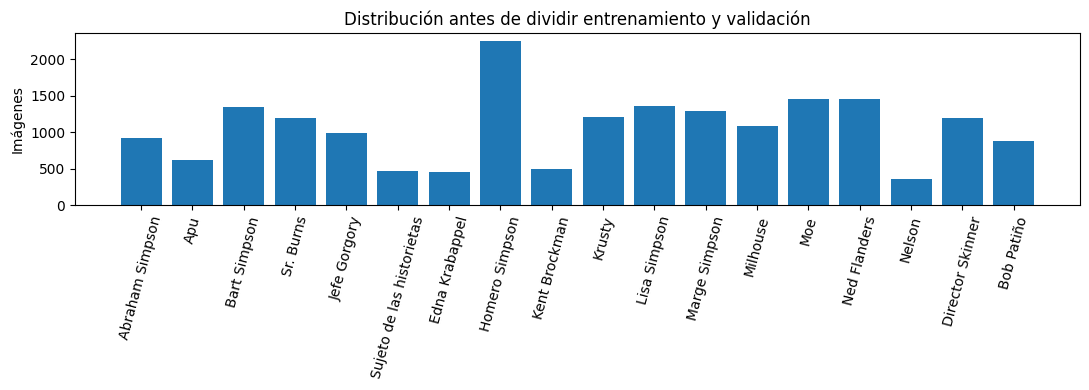

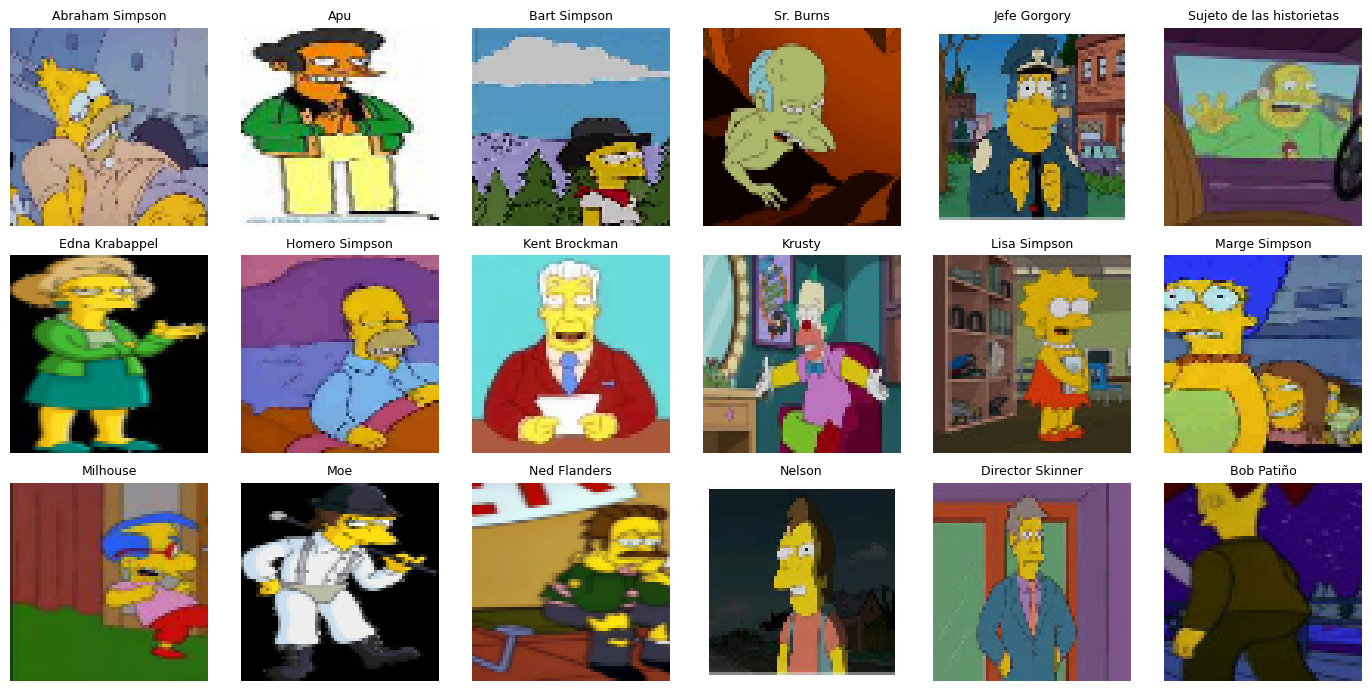

In [4]:
indices_train, indices_val = train_test_split(
    np.arange(len(y)), test_size=0.20, random_state=SEMILLA_PARTICION, stratify=y)
assert not set(indices_train) & set(indices_val)
assert len(indices_train) + len(indices_val) == len(y)
conteos = pd.DataFrame({
    "personaje": NOMBRES, "entrenamiento": np.bincount(y[indices_train], minlength=NUM_CLASSES),
    "validacion": np.bincount(y[indices_val], minlength=NUM_CLASSES),
    "prueba": np.bincount(y_test, minlength=NUM_CLASSES),
})
mostrar_tabla("Distribución por conjunto", conteos)
mostrar_distribucion(y, X_raw, NOMBRES, FIGURAS_DIR)
conteos.to_csv(RESULTADOS_DIR / "conteos.csv", index=False)


In [ ]:
# Conteos antes de dividir y relación entre las clases extremas.
totales_por_personaje = conteos.set_index("personaje")[["entrenamiento", "validacion"]].sum(axis=1)
personaje_mayor = totales_por_personaje.idxmax()
personaje_menor = totales_por_personaje.idxmin()
mostrar_tabla("Clases con más y menos imágenes", pd.DataFrame({
    "personaje": [personaje_mayor, personaje_menor],
    "imagenes": [totales_por_personaje.max(), totales_por_personaje.min()],
}))
relacion_clases = totales_por_personaje.max() / totales_por_personaje.min()
print(f"Relación entre máximo y mínimo: {relacion_clases:.2f} a 1")
print(f"Imágenes de prueba por personaje: mínimo {conteos['prueba'].min()}, máximo {conteos['prueba'].max()}")


**Clases con más y menos imágenes**

,personaje,imagenes
0,Homero Simpson,2.246
1,Nelson,358


Relación entre máximo y mínimo: 6.27 a 1
Imágenes de prueba por personaje: mínimo 47, máximo 50


### Distribución y partición observadas

La partición produjo **15.193 imágenes de entrenamiento y 3.799 de validación**. Se conservaron las 18 clases en ambas partes, con índices separados y la misma división para todos los RUN.

Antes de dividir, Homero aporta 2.246 imágenes y Nelson 358. Ese desbalance justifica complementar accuracy con F1 macro. El conjunto de prueba está casi equilibrado, con entre 47 y 50 imágenes por personaje; sus promedios macro y ponderado pueden resultar cercanos.


## 4. Normalización

Las imágenes mantienen la estructura (alto, ancho, canales), sin aplanarse antes de las convoluciones, y sus píxeles se dividen por 255.

Todas las entradas se ajustan a 64 × 64: OpenCV redimensiona el alto y el ancho a ese tamaño, sin recorte ni relleno, por lo que puede cambiar la relación de aspecto original.

Entrenamiento, validación y prueba reciben el mismo escalado a `float32` en [0, 1] y las etiquetas se convierten a one-hot para utilizar entropía cruzada categórica y softmax de 18 salidas.

In [5]:
X_train = X_raw[indices_train].astype("float32") / 255.0
X_val = X_raw[indices_val].astype("float32") / 255.0
X_test = X_test_raw.astype("float32") / 255.0
y_train, y_val = y[indices_train], y[indices_val]
Y_train = keras.utils.to_categorical(y_train, NUM_CLASSES)
Y_val = keras.utils.to_categorical(y_val, NUM_CLASSES)
Y_test = keras.utils.to_categorical(y_test, NUM_CLASSES)
for imagenes, etiquetas in [(X_train, Y_train), (X_val, Y_val), (X_test, Y_test)]:
    assert imagenes.shape[1:] == (IMG_SIZE, IMG_SIZE, 3)
    assert imagenes.dtype == np.float32 and 0 <= imagenes.min() <= imagenes.max() <= 1
    assert etiquetas.shape == (len(imagenes), NUM_CLASSES) and np.all(etiquetas.sum(axis=1) == 1)
print("Train:", X_train.shape, "| Validación:", X_val.shape, "| Test:", X_test.shape)


Train: (15193, 64, 64, 3) | Validación: (3799, 64, 64, 3) | Test: (890, 64, 64, 3)


### Comprobación del preprocesamiento

Los controles ejecutados confirman entradas de **64 × 64 × 3**, con tipo `float32` y valores entre 0 y 1. Las etiquetas tienen 18 componentes one-hot y suman 1 por imagen. El mismo procedimiento se aplica a los tres conjuntos, sin estimar parámetros del preprocesamiento con datos de prueba.

El redimensionamiento permite comparar todas las imágenes con una entrada común. A cambio, puede eliminar detalles pequeños útiles para reconocer al personaje, una limitación relevante al inspeccionar ejemplos difíciles.


## 5. Arquitecturas del laboratorio y configuraciones

Se adaptan las redes simple y profunda del laboratorio **2.2.3 Redes Convolucionales**:

- **A:** Conv64 → pooling → Flatten → Dense128 → salida.
- **B:** Conv32 → Conv32 → pooling → Conv64 → pooling → Flatten → Dense512 → salida.

Las convoluciones usan kernel 3 × 3, stride 1, padding `valid` y ReLU; el pooling es 2 × 2. La salida es softmax de 18 clases. El tamaño de entrada es 64 × 64.

1. Primero se compara A/B sin dropout.

2. Luego, C/D usan la mejor arquitectura con dropout de 0,2/0,3 después del primer pooling y de la capa densa oculta.

3. Finalmente E/F cambian solo la tasa de aprendizaje de la mejor configuración A-D.

Se estudian arquitecturas completas: añadir capas también modifica la representación y el tamaño de Flatten. Los valores de dropout 0,2/0,3 proceden de la orientación del laboratorio. Adam con tasa 0,001 es la base fijada para esta comparación; 0,0003 y 0,003 exploran una tasa aproximadamente tres veces menor y otra tres veces mayor.

> Es importante notar que es una búsqueda acotada alrededor de la base, sin afirmar haber hallado un óptimo global.


La construcción de las redes se implementa en `crear_modelo`, dentro de `utilidades.py`. Las siguientes celdas definen las configuraciones, llaman a esa función y muestran sus capas y parámetros.

In [6]:
CONFIGURACIONES = {
    "A": {"id": "A", "arquitectura": "simple", "dropout": 0.0, "lr": 0.001, "referencia": None},
    "B": {"id": "B", "arquitectura": "profunda", "dropout": 0.0, "lr": 0.001, "referencia": "A"},
}
datos_arquitecturas = {}
for config in CONFIGURACIONES.values():
    keras.backend.clear_session()
    red = crear_modelo(config, IMG_SIZE, NUM_CLASSES)
    red.summary()
    capa_flatten = next(capa for capa in red.layers if isinstance(capa, Flatten))
    datos_arquitecturas[config["id"]] = {
        "parametros": int(red.count_params()),
        "entrada_flatten": tuple(capa_flatten.input.shape[1:]),
        "valores_flatten": int(capa_flatten.output.shape[-1]),
    }
del red, capa_flatten
keras.backend.clear_session()

Model: "cnn_A"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 64)     │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 61504)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     7,872,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         2,322 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,876,754 (30.05 MB)

 Trainable params: 7,876,754 (30.05 MB)

 Non-trainable params: 0 (0.00 B)

Model: "cnn_B"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,423,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         9,234 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,460,914 (24.65 MB)

 Trainable params: 6,460,914 (24.65 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Los parámetros y tamaños se obtienen de los modelos mostrados arriba.
mostrar_tabla("Parámetros y entrada a Flatten", pd.DataFrame.from_dict(
    datos_arquitecturas, orient="index").rename_axis("modelo"))
parametros_a = datos_arquitecturas["A"]["parametros"]
parametros_b = datos_arquitecturas["B"]["parametros"]
reduccion_parametros_pct = (parametros_a - parametros_b) / parametros_a * 100
print(f"Reducción de parámetros de B respecto de A: {reduccion_parametros_pct:.2f}%")


**Parámetros y entrada a Flatten**

,parametros,entrada_flatten,valores_flatten
modelo,,,
A,7.876.754,"(31, 31, 64)",61.504
B,6.460.914,"(14, 14, 64)",12.544


Reducción de parámetros de B respecto de A: 17.97%


### Lectura de las arquitecturas

La red A tiene **7.876.754 parámetros** y la B **6.460.914**, un **17,97% menos**.
A entrega 31 × 31 × 64 valores a Flatten (61.504) y B entrega 14 × 14 × 64 (12.544).
Esa reducción compensa que la capa densa de B tenga 512 unidades frente a 128 en A.

> Las diferencias de desempeño que se observen deben atribuirse a la arquitectura completa, pues cambian las convoluciones, la reducción espacial y la capa densa.
> C/D incorporarán dropout sobre la arquitectura que resulte elegida al comparar A y B en validación. Dropout actúa durante el entrenamiento y no añade parámetros entrenables.


## 6. Entrenamiento y selección automática

Un RUN es el entrenamiento independiente de una configuración con una semilla.

> Con seis configuraciones y tres semillas, se producen 18 entrenamientos, no 18 arquitecturas distintas.

**Condiciones de entrenamiento**

Cada RUN comienza con un modelo y un optimizador nuevos. Todos comparten estas condiciones:

- Optimizador **Adam** y batch de **64 imágenes**.
- Un máximo de **40 épocas**.
- Early stopping con paciencia de **8 épocas**, monitoreando la pérdida de validación.

El batch de 64 retoma el ejemplo del laboratorio. El máximo de 40 épocas y la paciencia de 8 permiten mantener un presupuesto comparable y tolerar oscilaciones de validación. Estas condiciones se fijaron para todos los RUN y no se optimizaron por separado.

**Dos decisiones diferentes**

Cada configuración se repite con las semillas **42, 123 y 456**. Para comparar sus resultados se distinguen dos decisiones:

1. **Qué pesos conservar en cada RUN.** El checkpoint guarda los pesos de la época con menor pérdida de validación. Al terminar, se recuperan y evalúan esos pesos antes de registrar las métricas. Se usa la pérdida porque considera las probabilidades asignadas; la época elegida puede ser distinta de la que obtuvo mayor accuracy.

2. **Qué configuración elegir.** Se compara la accuracy media de validación de las tres semillas, que resume la proporción de aciertos. Si hay empate, se utiliza, en este orden, el mayor F1 macro medio, el menor número de parámetros y el identificador. F1 macro complementa la comparación ante el desbalance entre personajes.

Ambos criterios se fijaron antes de observar el conjunto de prueba. El conjunto de prueba no interviene en ninguna de estas decisiones.

**Registro de la ejecución**

La traza de `fit()` se conserva en memoria para mostrar después el entrenamiento completo del modelo seleccionado. Todos los RUN se entrenan de nuevo al ejecutar las celdas de esta sección; no se reutilizan experimentos anteriores.


Las funciones de entrenamiento y selección están definidas en `utilidades.py`. Las celdas siguientes preparan sus entradas y las llaman en el orden descrito; los cálculos de respaldo permanecen visibles en el notebook.

In [7]:
RUNS = []

datos_entrenamiento = {
    "X_train": X_train, "Y_train": Y_train,
    "X_val": X_val, "Y_val": Y_val, "y_val": y_val,
}
ajustes_entrenamiento = {
    "img_size": IMG_SIZE, "num_classes": NUM_CLASSES,
    "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
    "paciencia": PACIENCIA, "carpeta_pesos": PESOS_DIR,
}

In [8]:
# Comparar las dos arquitecturas.
entrenar_configuraciones(
    ["A", "B"], CONFIGURACIONES, SEMILLAS,
    datos_entrenamiento, ajustes_entrenamiento, RUNS,
)
MEJOR_BASE = elegir_configuracion(RUNS, ["A", "B"], SEMILLAS)

Entrenamiento 1/18 | A_s42 | arquitectura=simple, dropout=0.0, lr=0.001
A_s42: val_accuracy=0.6399; mejor época=3
Entrenamiento 2/18 | A_s123 | arquitectura=simple, dropout=0.0, lr=0.001
A_s123: val_accuracy=0.6478; mejor época=3
Entrenamiento 3/18 | A_s456 | arquitectura=simple, dropout=0.0, lr=0.001
A_s456: val_accuracy=0.6162; mejor época=3
Entrenamiento 4/18 | B_s42 | arquitectura=profunda, dropout=0.0, lr=0.001
B_s42: val_accuracy=0.7452; mejor época=4
Entrenamiento 5/18 | B_s123 | arquitectura=profunda, dropout=0.0, lr=0.001
B_s123: val_accuracy=0.7107; mejor época=2
Entrenamiento 6/18 | B_s456 | arquitectura=profunda, dropout=0.0, lr=0.001
B_s456: val_accuracy=0.7097; mejor época=2


In [9]:
# Comparar dropout sobre la arquitectura elegida.
for nombre, dropout in [("C", 0.2), ("D", 0.3)]:
    CONFIGURACIONES[nombre] = {**CONFIGURACIONES[MEJOR_BASE], "id": nombre,
                              "dropout": dropout, "referencia": MEJOR_BASE}
print("Base para comparar dropout:", MEJOR_BASE)
entrenar_configuraciones(
    ["C", "D"], CONFIGURACIONES, SEMILLAS,
    datos_entrenamiento, ajustes_entrenamiento, RUNS,
)

MEJOR_PREVIA = elegir_configuracion(RUNS, ["A", "B", "C", "D"], SEMILLAS)

Base para comparar dropout: B
Entrenamiento 7/18 | C_s42 | arquitectura=profunda, dropout=0.2, lr=0.001
C_s42: val_accuracy=0.7481; mejor época=3
Entrenamiento 8/18 | C_s123 | arquitectura=profunda, dropout=0.2, lr=0.001
C_s123: val_accuracy=0.7457; mejor época=3
Entrenamiento 9/18 | C_s456 | arquitectura=profunda, dropout=0.2, lr=0.001
C_s456: val_accuracy=0.7718; mejor época=4
Entrenamiento 10/18 | D_s42 | arquitectura=profunda, dropout=0.3, lr=0.001
D_s42: val_accuracy=0.7757; mejor época=5
Entrenamiento 11/18 | D_s123 | arquitectura=profunda, dropout=0.3, lr=0.001
D_s123: val_accuracy=0.7634; mejor época=4
Entrenamiento 12/18 | D_s456 | arquitectura=profunda, dropout=0.3, lr=0.001
D_s456: val_accuracy=0.7805; mejor época=6


In [10]:
# Comparar tasas de aprendizaje y seleccionar la configuración final.
for nombre, lr in [("E", 0.0003), ("F", 0.003)]:
    CONFIGURACIONES[nombre] = {**CONFIGURACIONES[MEJOR_PREVIA], "id": nombre,
                              "lr": lr, "referencia": MEJOR_PREVIA}
print("Referencia para comparar tasas:", MEJOR_PREVIA)
entrenar_configuraciones(
    ["E", "F"], CONFIGURACIONES, SEMILLAS,
    datos_entrenamiento, ajustes_entrenamiento, RUNS,
)
assert len(RUNS) == len({run["id"] for run in RUNS}) == 18
CONFIG_ELEGIDA = elegir_configuracion(RUNS, list(CONFIGURACIONES), SEMILLAS)
print("Configuración elegida por validación:", CONFIG_ELEGIDA)

Referencia para comparar tasas: D
Entrenamiento 13/18 | E_s42 | arquitectura=profunda, dropout=0.3, lr=0.0003
E_s42: val_accuracy=0.7710; mejor época=9
Entrenamiento 14/18 | E_s123 | arquitectura=profunda, dropout=0.3, lr=0.0003
E_s123: val_accuracy=0.7694; mejor época=10
Entrenamiento 15/18 | E_s456 | arquitectura=profunda, dropout=0.3, lr=0.0003
E_s456: val_accuracy=0.7631; mejor época=9
Entrenamiento 16/18 | F_s42 | arquitectura=profunda, dropout=0.3, lr=0.003
F_s42: val_accuracy=0.7149; mejor época=5
Entrenamiento 17/18 | F_s123 | arquitectura=profunda, dropout=0.3, lr=0.003
F_s123: val_accuracy=0.6968; mejor época=4
Entrenamiento 18/18 | F_s456 | arquitectura=profunda, dropout=0.3, lr=0.003
F_s456: val_accuracy=0.7028; mejor época=5
Configuración elegida por validación: D


In [ ]:
# Totales del experimento a partir de los registros de cada entrenamiento.
epocas_ejecutadas = [run["epocas"] for run in RUNS]
segundos_fit = sum(run["segundos"] for run in RUNS)
detenciones_tempranas = sum(run["detencion"] == "early_stopping" for run in RUNS)
print(f"Entrenamientos completados: {len(RUNS)}")
print(f"Épocas totales: {sum(epocas_ejecutadas)} | mínimo: {min(epocas_ejecutadas)} | máximo: {max(epocas_ejecutadas)}")
print(f"Tiempo total de fit: {segundos_fit:.2f} segundos = {segundos_fit / 60:.2f} minutos")
print(f"Detenciones por early stopping: {detenciones_tempranas}/{len(RUNS)}")


Entrenamientos completados: 18
Épocas totales: 228 | mínimo: 10 | máximo: 18
Tiempo total de fit: 210.62 segundos = 3.51 minutos
Detenciones por early stopping: 18/18


### Ejecución y decisiones intermedias

Se completaron los **18 entrenamientos**, con las semillas 42, 123 y 456 en cada configuración.

- B fue la mejor base, así que C/D usan su arquitectura.
- D fue la mejor entre A-D y sirvió de referencia a E/F, que modifican únicamente la tasa de aprendizaje.

La siguiente sección desglosa las métricas que respaldan estas decisiones.

Todos terminaron por early stopping, con sus checkpoints seleccionados por el **mínimo de pérdida de validación**. Se ejecutaron **228 épocas**, entre 10 y 18 por entrenamiento, sin alcanzar el límite de 40.

Las llamadas a `fit()` sumaron **210,62 segundos**, unos 3,51 minutos. Ese tiempo excluye descarga, carga, evaluaciones y gráficos. La GPU utilizada en Colab en esta ejecución fue G4.


## 7. Comparación en validación

La tabla individual muestra cada RUN y la época elegida por pérdida. El resumen compara la media y la desviación muestral de accuracy de las tres semillas, junto con F1 macro. La desviación describe estas repeticiones; no es un intervalo de confianza ni demuestra estabilidad general.

Para interpretar los cambios, se comparan:
- A con B
- C/D con la base que comparten
- E/F, con su referencia A-D

Estas seis curvas muestran la evolución de accuracy de validación y su variación entre semillas.
Las marcas X identifican los checkpoints de mínima pérdida que se evaluaron para la tabla, no se comparan solo los extremos finales de las curvas.
El sobreajuste del principal se examina en las secciones 8 y 9, mediante sus curvas de entrenamiento/validación y su brecha en inferencia.
Un ajuste puede empeorar las métricas y debe conservarse en la comparación.


In [11]:
columnas_runs = [
    "id", "config_id", "semilla", "parametros", "epocas", "mejor_epoca",
    "detencion", "val_loss", "val_accuracy", "val_f1_macro", "segundos",
]
tabla_runs = pd.DataFrame([{columna: run[columna] for columna in columnas_runs} for run in RUNS])
resumen = resumir_runs(RUNS, list(CONFIGURACIONES), SEMILLAS)

mostrar_tabla("Configuraciones comparadas", pd.DataFrame(CONFIGURACIONES.values()))
mostrar_tabla("Resultados de cada entrenamiento - duración en segundos", tabla_runs)
mostrar_tabla("Resumen de validación - media y desviación entre semillas", resumen)

tabla_runs.to_csv(RESULTADOS_DIR / "entrenamientos.csv", index=False)
resumen.to_csv(RESULTADOS_DIR / "resumen_validacion.csv", index=False)

**Configuraciones comparadas**

,id,arquitectura,dropout,lr,referencia
0,A,simple,"0,0000","0,0010",None
1,B,profunda,"0,0000","0,0010",A
2,C,profunda,"0,2000","0,0010",B
3,D,profunda,"0,3000","0,0010",B
4,E,profunda,"0,3000","0,0003",D
5,F,profunda,"0,3000","0,0030",D


**Resultados de cada entrenamiento - duración en segundos**

,id,config_id,semilla,parametros,epocas,mejor_epoca,detencion,val_loss,val_accuracy,val_f1_macro,segundos
0,A_s42,A,42,7.876.754,11,3,early_stopping,"1,2945","0,6399","0,6280","14,0163"
1,A_s123,A,123,7.876.754,11,3,early_stopping,"1,2764","0,6478","0,6369","8,4435"
2,A_s456,A,456,7.876.754,11,3,early_stopping,"1,3753","0,6162","0,6105","8,4804"
3,B_s42,B,42,6.460.914,12,4,early_stopping,"1,0488","0,7452","0,7449","14,7229"
4,B_s123,B,123,6.460.914,10,2,early_stopping,"0,9867","0,7107","0,7002","8,9819"
5,B_s456,B,456,6.460.914,10,2,early_stopping,"1,0383","0,7097","0,7034","9,0256"
6,C_s42,C,42,6.460.914,11,3,early_stopping,"0,8922","0,7481","0,7422","11,2076"
7,C_s123,C,123,6.460.914,11,3,early_stopping,"0,8775","0,7457","0,7317","10,5312"
8,C_s456,C,456,6.460.914,12,4,early_stopping,"0,8449","0,7718","0,7700","11,2500"
9,D_s42,D,42,6.460.914,13,5,early_stopping,"0,8359","0,7757","0,7750","11,8254"


**Resumen de validación - media y desviación entre semillas**

,configuracion,parametros,val_accuracy_media,val_accuracy_std,val_f1_macro_media,val_loss_media
0,A,7.876.754,"0,6346","0,0164","0,6251","1,3154"
1,B,6.460.914,"0,7219","0,0202","0,7162","1,0246"
2,C,6.460.914,"0,7552","0,0144","0,7480","0,8716"
3,D,6.460.914,"0,7732","0,0088","0,7743","0,8409"
4,E,6.460.914,"0,7678","0,0042","0,7653","0,8842"
5,F,6.460.914,"0,7048","0,0092","0,7029","1,0684"


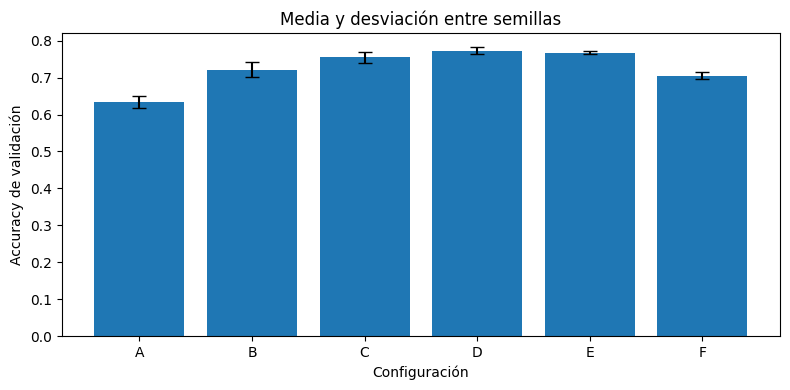

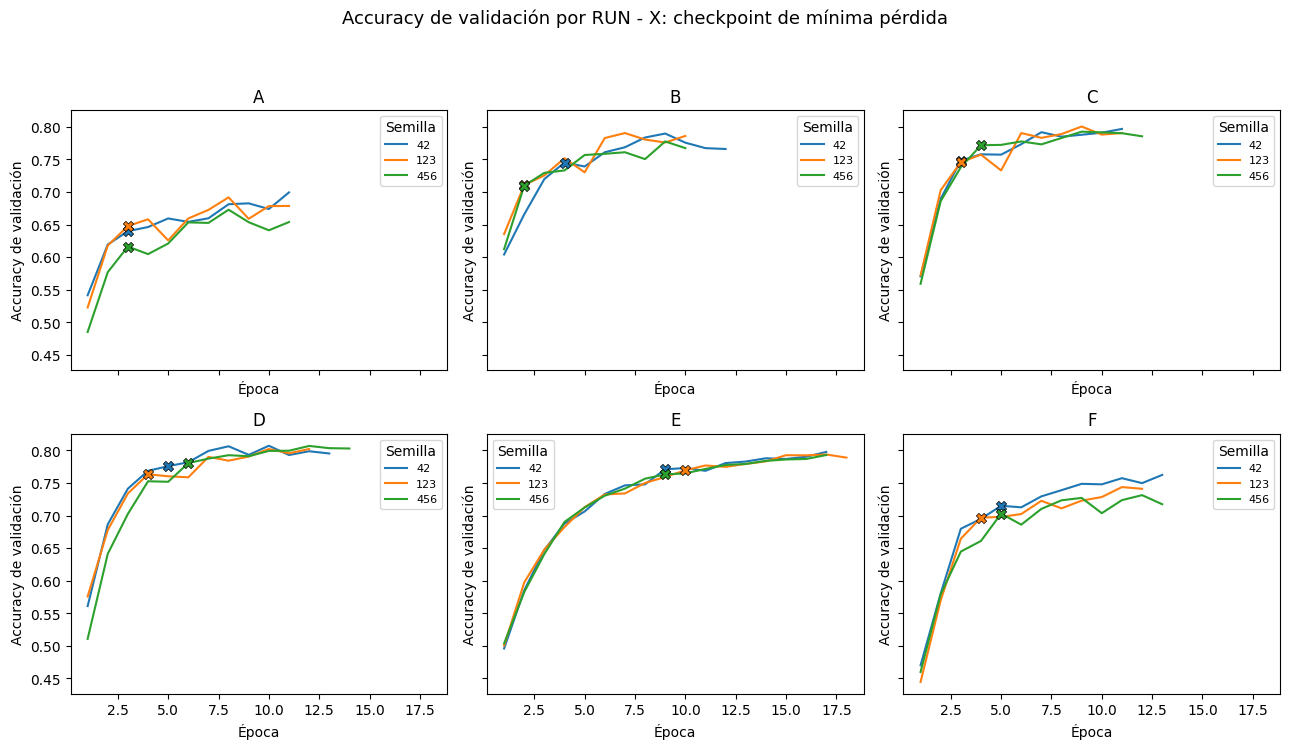

In [12]:
graficar_comparacion(resumen, RUNS, CONFIGURACIONES, FIGURAS_DIR)

In [ ]:
# Multiplicar una proporción por 100 permite expresarla como porcentaje.
resumen_porcentual = resumen[["configuracion", "val_accuracy_media", "val_accuracy_std"]].copy()
resumen_porcentual["val_accuracy_media"] *= 100
resumen_porcentual["val_accuracy_std"] *= 100
resumen_porcentual = resumen_porcentual.rename(columns={
    "val_accuracy_media": "accuracy_media_pct", "val_accuracy_std": "desviacion_pp",
})
mostrar_tabla("Validación en porcentajes y puntos porcentuales", resumen_porcentual)

# Cada diferencia usa las dos configuraciones entrenadas con la misma semilla.
accuracy_por_semilla = tabla_runs.pivot(index="semilla", columns="config_id", values="val_accuracy")
diferencias = []
for nueva, referencia in [("B", "A"), ("C", "B"), ("D", "B"), ("D", "C"), ("E", "D"), ("F", "D")]:
    cambios_pp = (accuracy_por_semilla[nueva] - accuracy_por_semilla[referencia]) * 100
    diferencias.append({
        "comparacion": f"{nueva} - {referencia}",
        **{f"semilla_{semilla}_pp": cambios_pp.loc[semilla] for semilla in SEMILLAS},
        "media_pp": cambios_pp.mean(),
    })
mostrar_tabla("Diferencias de accuracy en puntos porcentuales", pd.DataFrame(diferencias))
f1_medio_elegido = resumen.set_index("configuracion").loc[CONFIG_ELEGIDA, "val_f1_macro_media"]
print(f"F1 macro medio de {CONFIG_ELEGIDA}: {f1_medio_elegido:.6f}")


**Validación en porcentajes y puntos porcentuales**

,configuracion,accuracy_media_pct,desviacion_pp
0,A,"63,4641","1,6439"
1,B,"72,1857","2,0219"
2,C,"75,5199","1,4410"
3,D,"77,3186","0,8834"
4,E,"76,7834","0,4179"
5,F,"70,4835","0,9248"


**Diferencias de accuracy en puntos porcentuales**

,comparacion,semilla_42_pp,semilla_123_pp,semilla_456_pp,media_pp
0,B - A,"10,5291","6,2911","9,3446","8,7216"
1,C - B,"0,2895","3,5009","6,2122","3,3342"
2,D - B,"3,0534","5,2645","7,0808","5,1329"
3,D - C,"2,7639","1,7636","0,8686","1,7987"
4,E - D,"-0,4738","0,6054","-1,7373","-0,5352"
5,F - D,"-6,0805","-6,6596","-7,7652","-6,8351"


F1 macro medio de D: 0.774336


### Comparación de las configuraciones

**Arquitectura:** B supera A en **8,7216 puntos porcentuales**, con ventaja en las tres semillas. La red profunda resulta más adecuada entre estas dos alternativas y también tiene menos parámetros.

**Dropout:** C mejora B en **3,3342 puntos**, y D mejora B en **5,1329 puntos**. D supera C en las tres semillas, con una diferencia media de **1,7987 puntos**. También tiene mayor F1 macro y menor pérdida de validación en las tres comparaciones. Estos resultados favorecen 0,3 dentro del experimento; tres repeticiones sobre una sola partición no demuestran superioridad general ni significancia estadística.

**Tasa de aprendizaje:** E obtiene **0,5352 puntos menos** que D en promedio. E mejora D con semilla 123 en 0,6054 puntos, pero empeora con 42 y 456 en 0,4738 y 1,7373 puntos. F queda **6,8351 puntos por debajo** de D y empeora en las tres semillas. La tasa 0,001 conserva la mejor media dentro de las opciones probadas; E es la alternativa más cercana en accuracy media.

Las cifras corresponden a los checkpoints de mínima pérdida, no al máximo histórico de accuracy de cada entrenamiento. La desviación es muestral y describe una única partición con tres semillas, por lo que no se puede tomar como un intervalo de confianza.

Similar a lo mencionado en la sección 5, estas son búsquedas acotadas.

## 8. Registro del entrenamiento del modelo principal

La configuración ganadora se elige mediante validación y su RUN con semilla 42 se fija como modelo principal antes de evaluar el conjunto de prueba. No se seleccionará después la semilla que obtenga mayor accuracy de prueba.

Se muestra la traza original completa y el historial del RUN principal, como solicitan las sugerencias. La línea vertical de las curvas marca el mínimo de pérdida de validación utilizado por el checkpoint. Las métricas de `fit()` con dropout activo no equivalen a una evaluación posterior en modo inferencia.


In [13]:
PRINCIPAL = next(run for run in RUNS if run["config_id"] == CONFIG_ELEGIDA and run["semilla"] == SEMILLA_PRINCIPAL)
print("RUN principal:", PRINCIPAL["id"])
print("Configuración:", CONFIGURACIONES[CONFIG_ELEGIDA])
print("Época elegida por val_loss:", PRINCIPAL["mejor_epoca"])

RUN principal: D_s42
Configuración: {'id': 'D', 'arquitectura': 'profunda', 'dropout': 0.3, 'lr': 0.001, 'referencia': 'B'}
Época elegida por val_loss: 5


In [14]:
display(Markdown("**Registro completo del entrenamiento principal**"))
print(PRINCIPAL["traza_fit"])

**Registro completo del entrenamiento principal**

Epoch 1/40
238/238 - 5s - 20ms/step - accuracy: 0.3781 - loss: 2.0450 - val_accuracy: 0.5609 - val_loss: 1.5159
Epoch 2/40
238/238 - 1s - 3ms/step - accuracy: 0.6407 - loss: 1.2113 - val_accuracy: 0.6865 - val_loss: 1.1113
Epoch 3/40
238/238 - 1s - 3ms/step - accuracy: 0.7519 - loss: 0.8240 - val_accuracy: 0.7412 - val_loss: 0.9030
Epoch 4/40
238/238 - 1s - 3ms/step - accuracy: 0.8309 - loss: 0.5498 - val_accuracy: 0.7686 - val_loss: 0.8466
Epoch 5/40
238/238 - 1s - 3ms/step - accuracy: 0.8798 - loss: 0.3804 - val_accuracy: 0.7757 - val_loss: 0.8359
Epoch 6/40
238/238 - 1s - 2ms/step - accuracy: 0.9171 - loss: 0.2605 - val_accuracy: 0.7818 - val_loss: 0.8990
Epoch 7/40
238/238 - 1s - 2ms/step - accuracy: 0.9358 - loss: 0.1981 - val_accuracy: 0.7992 - val_loss: 0.9062
Epoch 8/40
238/238 - 1s - 2ms/step - accuracy: 0.9572 - loss: 0.1379 - val_accuracy: 0.8063 - val_loss: 0.9379
Epoch 9/40
238/238 - 1s - 2ms/step - accuracy: 0.9634 - loss: 0.1126 - val_accuracy: 0.7931 - val_loss: 1.0650


**Métricas por época del entrenamiento principal**

,accuracy,loss,val_accuracy,val_loss
epoca,,,,
1,"0,3781","2,0450","0,5609","1,5159"
2,"0,6407","1,2113","0,6865","1,1113"
3,"0,7519","0,8240","0,7412","0,9030"
4,"0,8309","0,5498","0,7686","0,8466"
5,"0,8798","0,3804","0,7757","0,8359"
6,"0,9171","0,2605","0,7818","0,8990"
7,"0,9358","0,1981","0,7992","0,9062"
8,"0,9572","0,1379","0,8063","0,9379"
9,"0,9634","0,1126","0,7931","1,0650"


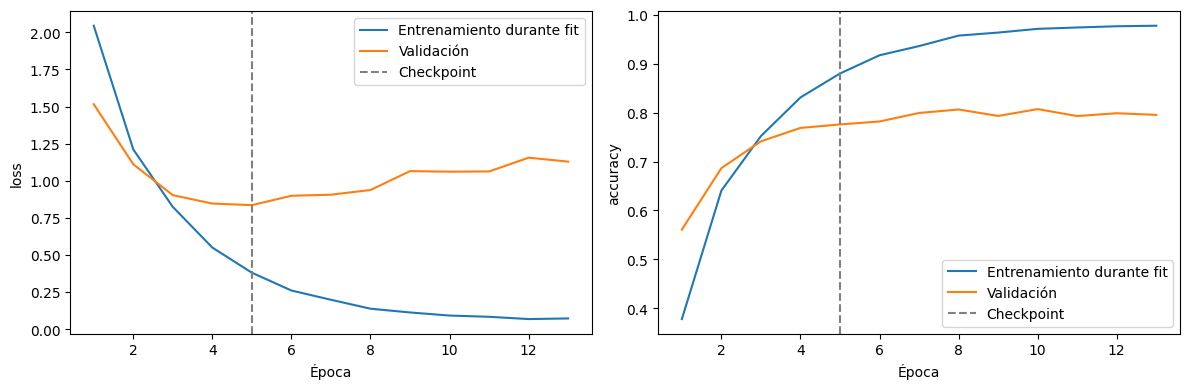

In [15]:
historial_principal = pd.DataFrame(PRINCIPAL["historial"])
historial_principal.index = np.arange(1, len(historial_principal) + 1)
historial_principal.index.name = "epoca"
mostrar_tabla("Métricas por época del entrenamiento principal", historial_principal)
graficar_historial(historial_principal, PRINCIPAL["mejor_epoca"], FIGURAS_DIR)

In [ ]:
# El checkpoint se elige por pérdida, aunque otra época tenga más aciertos.
epoca_minima_perdida = int(historial_principal["val_loss"].idxmin())
epoca_maxima_accuracy = int(historial_principal["val_accuracy"].idxmax())
hitos_principal = []
for criterio, epoca in [("Mínima pérdida", epoca_minima_perdida),
                        ("Máxima accuracy", epoca_maxima_accuracy)]:
    hitos_principal.append({
        "criterio": criterio, "epoca": epoca,
        "val_loss": historial_principal.loc[epoca, "val_loss"],
        "val_accuracy_pct": historial_principal.loc[epoca, "val_accuracy"] * 100,
        "fit_accuracy_pct": historial_principal.loc[epoca, "accuracy"] * 100,
    })
mostrar_tabla("Épocas destacadas del modelo principal", pd.DataFrame(hitos_principal))
perdida_checkpoint = historial_principal.loc[epoca_minima_perdida, "val_loss"]
print(f"Pérdida de validación del checkpoint: {perdida_checkpoint:.6f}")
print(f"Épocas ejecutadas: {len(historial_principal)} | épocas posteriores al mínimo: {len(historial_principal) - epoca_minima_perdida}")


**Épocas destacadas del modelo principal**

,criterio,epoca,val_loss,val_accuracy_pct,fit_accuracy_pct
0,Mínima pérdida,5,"0,8359","77,5730","87,9813"
1,Máxima accuracy,10,"1,0613","80,7054","97,1039"


Pérdida de validación del checkpoint: 0.835919
Épocas ejecutadas: 13 | épocas posteriores al mínimo: 8


### Época elegida y evolución del principal

El principal es **D_s42**: arquitectura profunda, dropout de 0,3 en dos posiciones y Adam con tasa 0,001. Entrenó **13 épocas** y recuperó la **época 5**, con pérdida de validación **0,835919** y accuracy **77,5730%**.

La accuracy de validación alcanza su máximo histórico en la época 10 (**80,7054%**), pero ese no es el checkpoint evaluado. Se respetó el criterio de menor pérdida establecido antes de entrenar. Accuracy cuenta aciertos; la entropía cruzada considera también las probabilidades, de modo que sus mejores épocas pueden diferir.

Después de la época 5, la pérdida de entrenamiento presenta una tendencia descendente mientras la pérdida de validación aumenta y permanece por encima del mínimo. Ese comportamiento es consistente con sobreajuste. Early stopping conserva el estado elegido y termina después de ocho épocas sin mejorar la pérdida, sin demostrar que el sobreajuste haya desaparecido.


## 9. Evaluación final y métricas por personaje

Se evalúan los tres checkpoints de la configuración elegida, sin volver a ajustar el modelo a partir del conjunto de prueba. El resultado principal corresponde a la semilla 42; las otras dos permiten describir la variación observada.

Accuracy mide aciertos globales. La precisión relaciona los aciertos de una clase con sus predicciones; recall mide cuántos de sus ejemplos reales se recuperan. F1 combina ambas medidas; su promedio macro da el mismo peso a cada personaje. La pérdida de todas las tablas se obtiene con Keras, igual que durante el entrenamiento.

Para medir el sobreajuste del principal se evalúan entrenamiento y validación con los mismos pesos y dropout desactivado. Las conclusiones deberán considerar también las distribuciones y dificultad de los conjuntos.


In [16]:
datos_evaluacion = {
    **datos_entrenamiento,
    "X_test": X_test, "Y_test": Y_test, "y_test": y_test,
}
EVALUACIONES_TEST, PROB_PRINCIPAL, BRECHA = evaluar_configuracion(
    CONFIGURACIONES[CONFIG_ELEGIDA], RUNS, SEMILLAS, SEMILLA_PRINCIPAL,
    datos_evaluacion, ajustes_entrenamiento, NOMBRES,
)

Model: "cnn_D"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 60, 60, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     6,423,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 18)             │         9,234 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,460,914 (24.65 MB)

 Trainable params: 6,460,914 (24.65 MB)

 Non-trainable params: 0 (0.00 B)

In [17]:
principal_test = next(r for r in EVALUACIONES_TEST if r["semilla"] == SEMILLA_PRINCIPAL)
tabla_test = pd.DataFrame([{k: r[k] for k in (
    "semilla", "loss", "accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted")}
    for r in EVALUACIONES_TEST])
metricas_clase = pd.DataFrame({nombre: principal_test["reporte"][nombre] for nombre in NOMBRES}).T
mostrar_tabla("Resultados de prueba por semilla", tabla_test)
mostrar_tabla("Prueba: media y desviación entre semillas",
              tabla_test.drop(columns="semilla").agg(["mean", "std"]))
mostrar_tabla("Métricas por personaje - modelo principal", metricas_clase)
mostrar_tabla("Modelo principal en modo inferencia", pd.DataFrame([{"conjunto": "train", **BRECHA["train"]},
                      {"conjunto": "validacion", **BRECHA["validacion"]}]))
print(f"Brecha de accuracy entre entrenamiento y validación: {BRECHA['train_menos_val_accuracy']:.4f}")
tabla_test.to_csv(RESULTADOS_DIR / "prueba_por_semilla.csv", index=False)
metricas_clase.to_csv(RESULTADOS_DIR / "metricas_por_clase.csv", index_label="personaje")


metricas_inferencia = pd.DataFrame([
    {"conjunto": "Entrenamiento", **BRECHA["train"]},
    {"conjunto": "Validación", **BRECHA["validacion"]},
])
metricas_inferencia.to_csv(RESULTADOS_DIR / "evaluacion_modelo_principal.csv", index=False)

resumen_test = pd.DataFrame({
    "metrica": ["Accuracy", "Precisión macro", "Recall macro", "F1 macro", "F1 ponderado", "Pérdida Keras"],
    "principal": tabla_test.set_index("semilla").loc[
        SEMILLA_PRINCIPAL, ["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "loss"]
    ].to_numpy(),
    "media": tabla_test[["accuracy", "precision_macro", "recall_macro", "f1_macro", "f1_weighted", "loss"]].mean().to_numpy(),
    "escala": [100, 1, 1, 1, 1, 1],
    "decimales": [4, 4, 4, 4, 4, 5],
})
resumen_test.to_csv(RESULTADOS_DIR / "resumen_prueba.csv", index=False)


**Resultados de prueba por semilla**

,semilla,loss,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
0,42,"0,3154","0,9292","0,9344","0,9290","0,9298","0,9298"
1,123,"0,4186","0,8899","0,8963","0,8897","0,8905","0,8907"
2,456,"0,3300","0,9180","0,9249","0,9179","0,9192","0,9193"


**Prueba: media y desviación entre semillas**

,loss,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted
mean,"0,3547","0,9124","0,9185","0,9122","0,9132","0,9133"
std,"0,0559","0,0203","0,0198","0,0203","0,0203","0,0203"


**Métricas por personaje - modelo principal**

,precision,recall,f1-score,support
Abraham Simpson,"0,8696","0,8333","0,8511",48
Apu,"0,9800","0,9800","0,9800",50
Bart Simpson,"0,8364","0,9200","0,8762",50
Sr. Burns,"0,9000","0,9375","0,9184",48
Jefe Gorgory,"0,9783","0,9000","0,9375",50
Sujeto de las historietas,"0,9783","0,9184","0,9474",49
Edna Krabappel,"1,0000","0,9000","0,9474",50
Homero Simpson,"0,8800","0,8800","0,8800",50
Kent Brockman,"0,9608","0,9800","0,9703",50
Krusty,"0,9804","1,0000","0,9901",50


**Modelo principal en modo inferencia**

,conjunto,accuracy,loss
0,train,"0,9591","0,1759"
1,validacion,"0,7757","0,8359"


Brecha de accuracy entre entrenamiento y validación: 0.1833


In [ ]:
# Conteos y métricas del principal, conservando la precisión citada en el texto.
aciertos_principal = int(np.sum(np.array(principal_test["predicciones"]) == y_test))
errores_principal = len(y_test) - aciertos_principal
evidencia_prueba = {
    "Aciertos / imágenes": f"{aciertos_principal} / {len(y_test)}",
    "Errores": str(errores_principal),
    "Accuracy por conteo (%)": f"{aciertos_principal / len(y_test) * 100:.4f}",
    "Pérdida Keras": f"{principal_test['loss']:.6f}",
    "Precisión macro": f"{principal_test['precision_macro']:.6f}",
    "Recall macro": f"{principal_test['recall_macro']:.6f}",
    "F1 macro": f"{principal_test['f1_macro']:.6f}",
    "Accuracy media de prueba (%)": f"{tabla_test['accuracy'].mean() * 100:.4f}",
    "Desviación muestral de accuracy (pp)": f"{tabla_test['accuracy'].std(ddof=1) * 100:.4f}",
}
mostrar_tabla("Cálculos de la evaluación final", pd.DataFrame(
    evidencia_prueba.items(), columns=["indicador", "valor"]))
mostrar_tabla("Accuracy de prueba por semilla (%)", tabla_test[["semilla", "accuracy"]].assign(
    accuracy=tabla_test["accuracy"] * 100).rename(columns={"accuracy": "accuracy_pct"}))

# Las brechas se calculan con evaluaciones de los mismos pesos en modo inferencia.
accuracy_inferencia = {
    "Entrenamiento": BRECHA["train"]["accuracy"],
    "Validación": BRECHA["validacion"]["accuracy"],
    "Prueba": principal_test["accuracy"],
}
mostrar_tabla("Accuracy en modo inferencia (%)", pd.DataFrame([
    {"conjunto": conjunto, "accuracy_pct": valor * 100}
    for conjunto, valor in accuracy_inferencia.items()
]))
brechas_pp = pd.DataFrame([
    {"comparacion": f"{conjunto} - Validación",
     "diferencia_pp": (accuracy_inferencia[conjunto] - accuracy_inferencia["Validación"]) * 100}
    for conjunto in ["Entrenamiento", "Prueba"]
])
mostrar_tabla("Brechas en puntos porcentuales", brechas_pp)

**Cálculos de la evaluación final**

,indicador,valor
0,Aciertos / imágenes,827 / 890
1,Errores,63
2,Accuracy por conteo (%),92.9213
3,Pérdida Keras,0.315363
4,Precisión macro,0.934425
5,Recall macro,0.929003
6,F1 macro,0.929824
7,Accuracy media de prueba (%),91.2360
8,Desviación muestral de accuracy (pp),2.0256


**Accuracy de prueba por semilla (%)**

,semilla,accuracy_pct
0,42,"92,9213"
1,123,"88,9888"
2,456,"91,7978"


**Accuracy en modo inferencia (%)**

,conjunto,accuracy_pct
0,Entrenamiento,"95,9060"
1,Validación,"77,5730"
2,Prueba,"92,9213"


**Brechas en puntos porcentuales**

,comparacion,diferencia_pp
0,Entrenamiento - Validación,"18,3330"
1,Prueba - Validación,"15,3483"


### Interpretación de la evaluación final

El modelo principal obtuvo **827 aciertos de 890 imágenes**, equivalentes a **92,9213% de accuracy**, con pérdida Keras **0,315363** y **F1 macro 0,929824**. Su precisión macro es 0,934425 y su recall macro 0,929003.

Las semillas 42, 123 y 456 alcanzaron respectivamente **92,9213%**, **88,9888%** y **91,7978%** en prueba. La media es **91,2360%**, con desviación muestral de **2,0256 puntos porcentuales**. En esta ejecución la semilla 42 obtiene el mayor valor de prueba; su condición de principal se había fijado previamente, sin utilizar ese resultado para elegirla. Los resultados muestran variación entre los tres entrenamientos.

En modo inferencia, el principal alcanza **95,9060% en entrenamiento** y **77,5730% en validación**: una brecha de **18,3330 puntos**. Persiste sobreajuste. La accuracy durante `fit()` en la época 5 fue 87,9813%; incluye dropout activo y cambios de pesos durante la época, por lo que no equivale a evaluar el checkpoint después de entrenar.

El conjunto de prueba supera la validación del principal en **15,3483 puntos**. Es compatible con la observación de las sugerencias sobre un conjunto de prueba más fácil y con las diferencias de distribución, pero los resultados no identifican por sí solos la causa ni garantizan ese rendimiento en otras imágenes.


## 10. Matriz de confusión y ejemplos

La matriz normalizada por fila indica qué proporción de cada personaje real se asigna a cada clase. Se mostrarán las confusiones con mayor cantidad de casos y una muestra reproducible de aciertos y errores del principal.

Cada imagen incluye su etiqueta de referencia, predicción y confianza softmax. Una confianza alta no garantiza una respuesta correcta. Los ejemplos sirven para describir dificultades observadas, sin deducir por sí solos las causas de los errores.


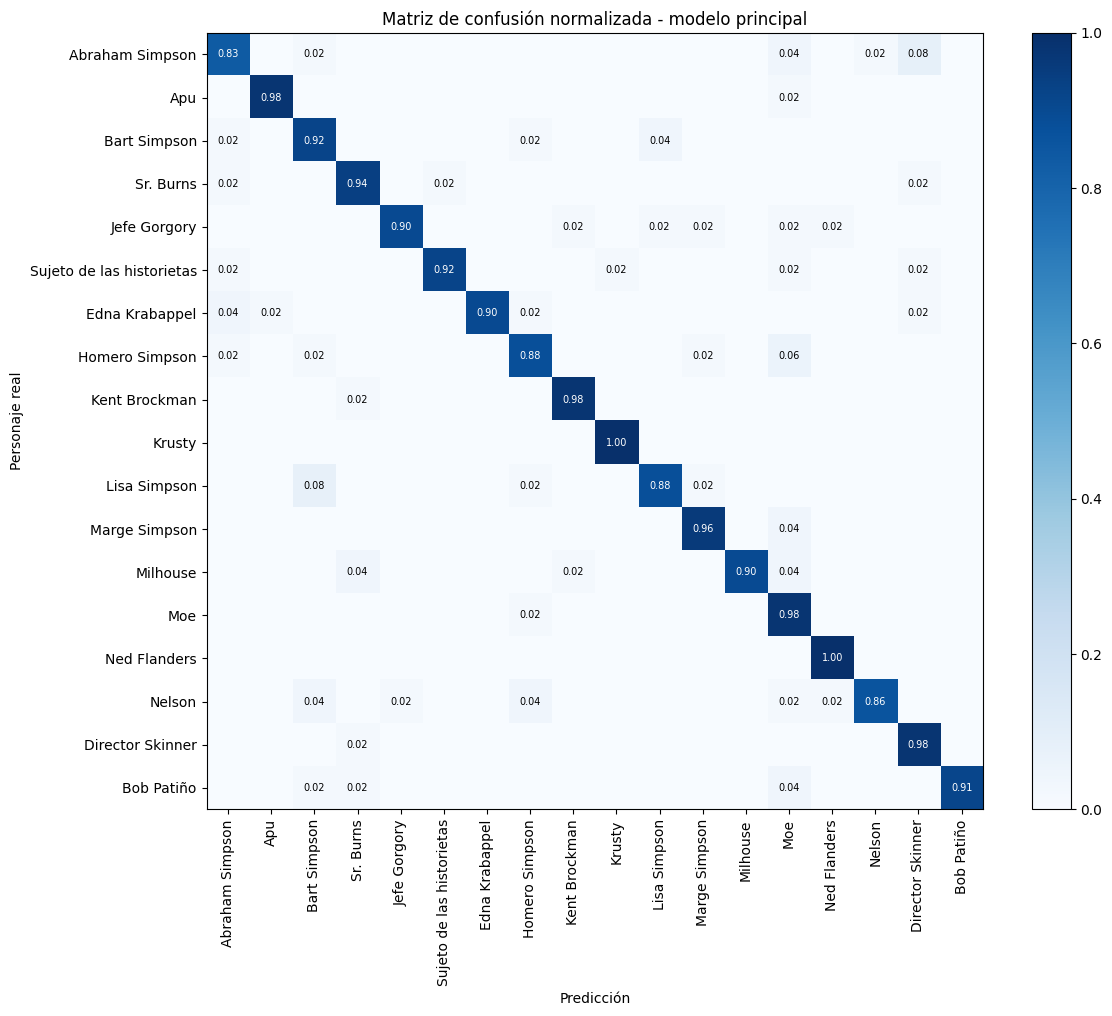

**Diez confusiones más frecuentes**

,real,prediccion,cantidad
0,Abraham Simpson,Director Skinner,4
1,Lisa Simpson,Bart Simpson,4
2,Homero Simpson,Moe,3
3,Abraham Simpson,Moe,2
4,Bart Simpson,Lisa Simpson,2
5,Edna Krabappel,Abraham Simpson,2
6,Marge Simpson,Moe,2
7,Milhouse,Sr. Burns,2
8,Milhouse,Moe,2
9,Nelson,Bart Simpson,2


In [18]:
pred_principal = PROB_PRINCIPAL.argmax(axis=1)
cm = np.array(principal_test["matriz"])
graficar_matriz(cm, NOMBRES, FIGURAS_DIR)
confusiones = [
    {"real": NOMBRES[i], "prediccion": NOMBRES[j], "cantidad": int(cm[i, j])}
    for i in range(NUM_CLASSES)
    for j in range(NUM_CLASSES)
    if i != j and cm[i, j]
]
confusiones_ordenadas = pd.DataFrame(confusiones).sort_values(
    "cantidad", ascending=False, kind="stable").reset_index(drop=True)
confusiones_frecuentes = confusiones_ordenadas.head(10)
mostrar_tabla("Diez confusiones más frecuentes", confusiones_frecuentes)
tabla_confusiones = confusiones_ordenadas.copy()
soportes = {nombre: int(cm[i].sum()) for i, nombre in enumerate(NOMBRES)}
tabla_confusiones["fraccion_clase_real"] = [
    fila.cantidad / soportes[fila.real] for fila in tabla_confusiones.itertuples()
]
tabla_confusiones.to_csv(RESULTADOS_DIR / "confusiones.csv", index=False)

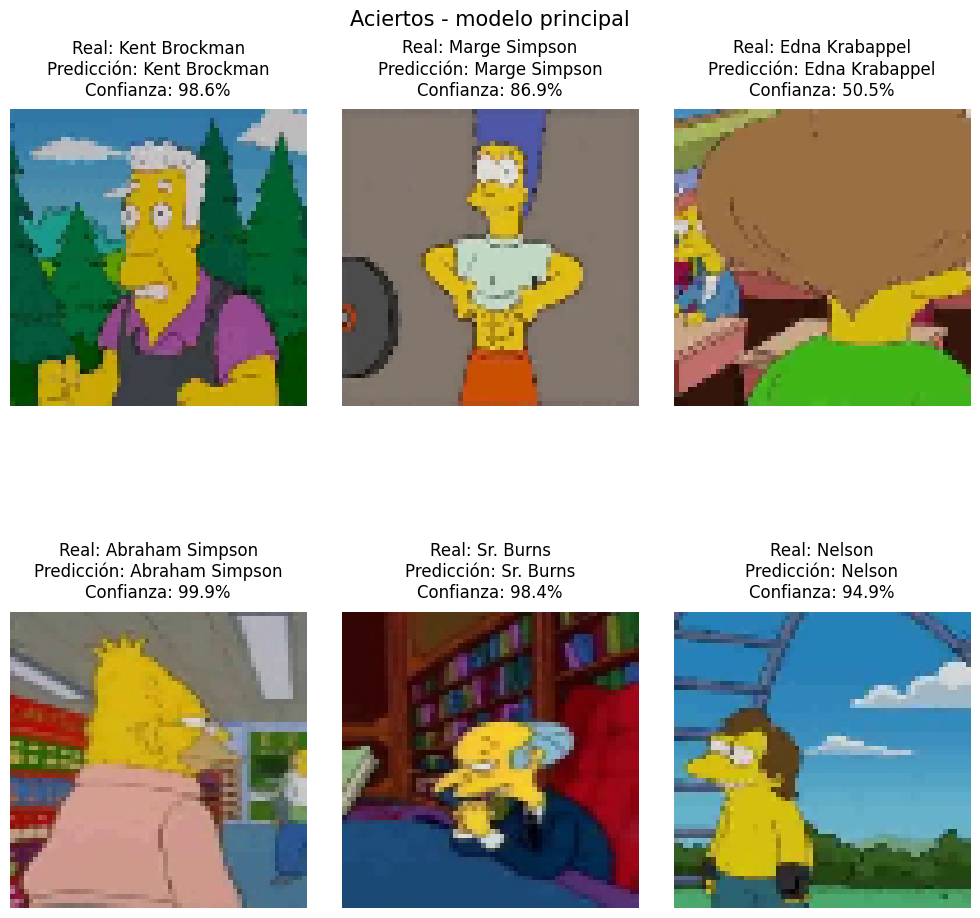

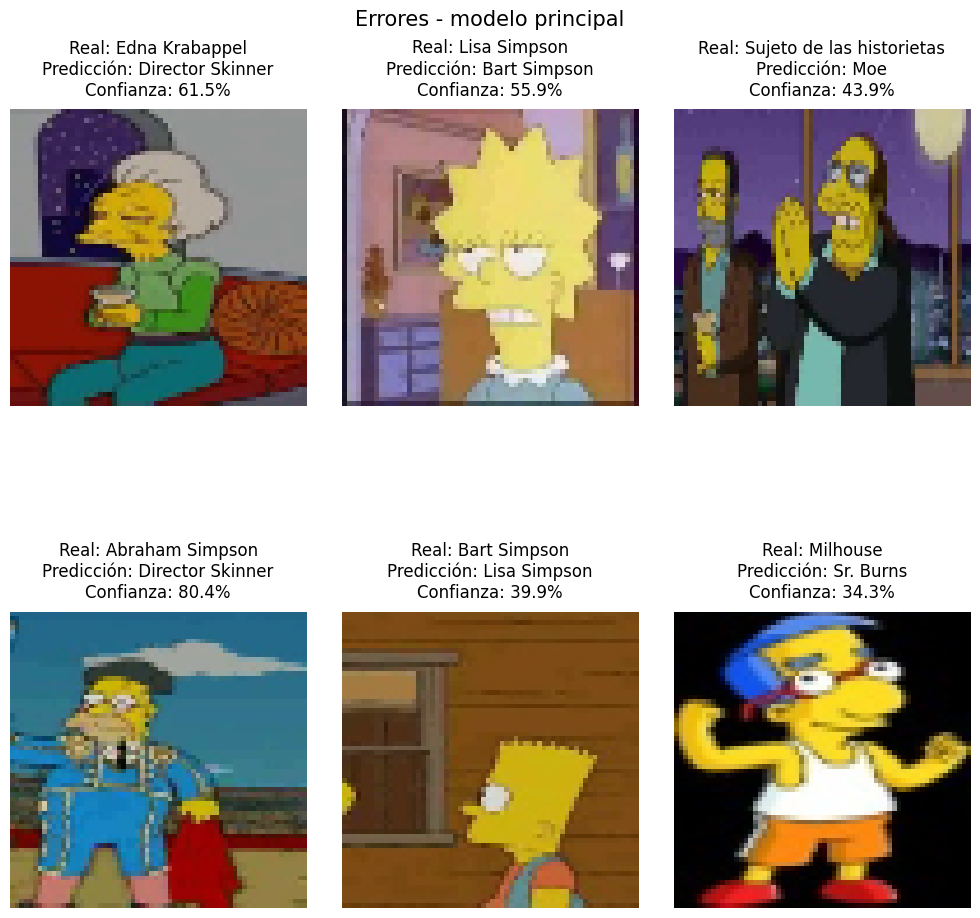

In [19]:
EJEMPLOS = mostrar_ejemplos(X_test_raw, y_test, PROB_PRINCIPAL, NOMBRES, FIGURAS_DIR)

In [ ]:
# La diagonal contiene los aciertos; las sumas por fila y columna dan los totales.
aciertos_por_personaje = np.diag(cm)
conteos_predicciones = pd.DataFrame({
    "personaje": NOMBRES,
    "reales": cm.sum(axis=1),
    "aciertos": aciertos_por_personaje,
    "omisiones": cm.sum(axis=1) - aciertos_por_personaje,
    "falsos_positivos": cm.sum(axis=0) - aciertos_por_personaje,
})
conteos_predicciones["recall_pct"] = aciertos_por_personaje / cm.sum(axis=1) * 100
mostrar_tabla("Conteos para comprobar las métricas por personaje", conteos_predicciones)
print("Menor recall:", metricas_clase["recall"].idxmin())
print("Menor precisión:", metricas_clase["precision"].idxmin())
print("Menor F1:", metricas_clase["f1-score"].idxmin())
print("Mayor F1:", metricas_clase["f1-score"].idxmax())
print("Personajes con F1 igual a 1:", int((metricas_clase["f1-score"] == 1).sum()))

mascara_errores = pred_principal != y_test
confianzas = PROB_PRINCIPAL.max(axis=1)
cantidad_errores = int(mascara_errores.sum())
confianza_media_errores_pct = confianzas[mascara_errores].mean() * 100
errores_confianza_alta = int((confianzas[mascara_errores] > 0.90).sum())
print(f"Confianza media de los errores: {confianza_media_errores_pct:.2f}%")
print(f"Errores con confianza superior al 90%: {errores_confianza_alta} de {cantidad_errores}")
print("Errores de confianza superior al 90% en la muestra:",
      int((confianzas[EJEMPLOS["Errores"]] > 0.90).sum()))


confusiones_principales = tabla_confusiones.head(3).copy()
confusiones_principales["porcentaje_clase_real"] = confusiones_principales["fraccion_clase_real"] * 100
mostrar_tabla("Frecuencia de las principales confusiones", confusiones_principales[
    ["real", "prediccion", "cantidad", "porcentaje_clase_real"]
])

**Conteos para comprobar las métricas por personaje**

,personaje,reales,aciertos,omisiones,falsos_positivos,recall_pct
0,Abraham Simpson,48,40,8,6,"83,3333"
1,Apu,50,49,1,1,"98,0000"
2,Bart Simpson,50,46,4,9,"92,0000"
3,Sr. Burns,48,45,3,5,"93,7500"
4,Jefe Gorgory,50,45,5,1,"90,0000"
5,Sujeto de las historietas,49,45,4,1,"91,8367"
6,Edna Krabappel,50,45,5,0,"90,0000"
7,Homero Simpson,50,44,6,6,"88,0000"
8,Kent Brockman,50,49,1,2,"98,0000"
9,Krusty,50,50,0,1,"100,0000"


**Frecuencia de las principales confusiones**

,real,prediccion,cantidad,porcentaje_clase_real
0,Abraham Simpson,Director Skinner,4,"8,3333"
1,Lisa Simpson,Bart Simpson,4,"8,0000"
2,Homero Simpson,Moe,3,"6,0000"


Menor recall: Abraham Simpson
Menor precisión: Moe
Menor F1: Abraham Simpson
Mayor F1: Krusty
Personajes con F1 igual a 1: 0
Confianza media de los errores: 53.94%
Errores con confianza superior al 90%: 2 de 63
Errores de confianza superior al 90% en la muestra: 0


### Resultados por personaje y errores

El principal comete **63 errores**. Abraham tiene el menor recall y el menor F1: **40 aciertos de 48**, o 83,33% de recall, y F1 de **0,8511**. Moe tiene la menor precisión (**0,7656**): recupera 49 de sus 50 imágenes, pero recibe 15 falsas predicciones de otros personajes. Krusty alcanza el F1 más alto (0,9901); ningún personaje obtiene F1 igual a 1 en este conjunto de prueba.

Las confusiones más frecuentes son **Abraham → Director Skinner** y **Lisa → Bart**, con cuatro imágenes cada una. También aparece Homero → Moe, con tres casos. La matriz y las métricas por clase permiten distinguir omisiones de una clase y predicciones incorrectas que recibe otra.

Las muestras presentan primeros planos, personajes de espaldas, vestuario poco habitual y escenas con varias figuras. Por ejemplo, Lisa aparece en primer plano y se predice Bart; Abraham lleva ropa y accesorios distintos de su aspecto habitual y se predice Director Skinner. Estas observaciones ilustran posibles dificultades, sin demostrar qué rasgos utilizó el modelo o la causa de cada error.

La confianza media de los errores es **53,94%**, y **2 de los 63** superan el 90%. También hay aciertos con confianza más moderada, como la muestra de Edna (50,5%). La confianza softmax no es una garantía de corrección; estas muestras no constituyen una evaluación de calibración.


## 11. Respaldo para comprobar e interpretar resultados

El notebook conserva tablas, curvas, métricas y ejemplos. Los datos numéricos completos se exportan a `resultados/resultados.json`, sin incrustar el JSON en los outputs. Incluye las etiquetas y predicciones de validación de cada RUN, los historiales y la evaluación de prueba.

Los CSV de `resultados/` resumen los RUN, la comparación de configuraciones y las métricas finales. Permiten analizar tablas pequeñas y consultar partes concretas del JSON mediante código cuando sea necesario.

Al finalizar, se comprime `resultados/` en `resultados.zip` y se inicia su descarga en Colab. Este archivo incluye el JSON, los CSV y las figuras necesarios para revisar la ejecución y actualizar el informe. Guarda también el notebook con sus salidas para la entrega. Los archivos temporales se pierden al eliminarse el runtime. Los CSV y el JSON se guardan en `resultados/`, disponible para versionar en Git. `data/` contiene el dataset y sigue excluida de Git.

Las figuras mostradas se exportan automáticamente a `resultados/figuras/` durante la misma ejecución. El informe utiliza esos PNG junto con los CSV de `resultados/`.


In [20]:
assert len(CONFIGURACIONES) == 6 and len(RUNS) == 18
assert len(EVALUACIONES_TEST) == len(SEMILLAS) == 3 and PROB_PRINCIPAL is not None
assert cm.sum() == len(y_test)
for nombre in CONFIGURACIONES:
    assert sorted(r["semilla"] for r in RUNS if r["config_id"] == nombre) == sorted(SEMILLAS)
assert all(r["epocas"] > 0 and r["traza_fit"] and len(r["predicciones_val"]) == len(y_val) for r in RUNS)
RESPALDO = {
    "formato": "ep2-resultados-2",
    "experimento": {"img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "max_epochs": MAX_EPOCHS,
                    "paciencia": PACIENCIA, "monitor": "val_loss", "mode": "min", "loss": "Keras categorical_crossentropy",
                    "semillas": SEMILLAS, "semilla_particion": SEMILLA_PARTICION},
    "clases": CLASES, "nombres": NOMBRES,
    "datos": {"archivos_train": archivos_train, "archivos_test": archivos_test,
              "excluidos_train": excluidos_train, "excluidos_test": excluidos_test, "conteos": conteos.to_dict(orient="records")},
    "particion": {"indices_train": indices_train.tolist(), "indices_val": indices_val.tolist(),
                  "y_train_completo": y.tolist(), "y_val": y_val.tolist()},
    "configuraciones": CONFIGURACIONES, "runs": RUNS,
    "resumen_validacion": resumen.to_dict(orient="records"),
    "seleccion": {"mejor_base": MEJOR_BASE, "mejor_previa": MEJOR_PREVIA,
                  "configuracion_final": CONFIG_ELEGIDA, "semilla_principal": SEMILLA_PRINCIPAL},
    "test": {"y_real": y_test.tolist(), "evaluaciones": EVALUACIONES_TEST,
             "probabilidades_principal": PROB_PRINCIPAL.tolist(), "ejemplos": EJEMPLOS},
    "brecha_inferencia": BRECHA,
}
ruta_respaldo = RESULTADOS_DIR / "resultados.json"
guardar_respaldo(RESPALDO, ruta_respaldo)
print("EJECUCIÓN COMPLETA: 18/18 RUN y evaluación final terminados.")
print(f"Configuración elegida: {CONFIG_ELEGIDA} | Semilla principal: {SEMILLA_PRINCIPAL}")
print(f"Respaldo completo: {ruta_respaldo.as_posix()}")
print(f"Figuras exportadas: {FIGURAS_DIR.as_posix()}/")


archivo_resultados = empaquetar_resultados(RESULTADOS_DIR)
print(f"Resultados listos: {archivo_resultados}")
try:
    from google.colab import files
except ImportError:
    print("El ZIP queda disponible en la carpeta de trabajo.")
else:
    files.download(archivo_resultados)


EJECUCIÓN COMPLETA: 18/18 RUN y evaluación final terminados.
Configuración elegida: D | Semilla principal: 42
Respaldo completo: resultados/resultados.json
Figuras exportadas: resultados/figuras/
Resultados listos: /content/resultados.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusiones y limitaciones

La comparación favoreció la arquitectura profunda del laboratorio: B mejoró A en 8,7216 puntos de accuracy media de validación, con menos parámetros. Añadir dropout mejoró esa base en las tres semillas. D, con probabilidad 0,3 en ambas posiciones, obtuvo la mayor accuracy media (**77,3186%**) y F1 macro medio (**0,774336**), con una ventaja de 1,7987 puntos frente a C.

La tasa de aprendizaje 0,0003 no mejoró la media de D y mostró resultados distintos según la semilla. La tasa 0,003 redujo el desempeño en las tres repeticiones. Se conserva 0,001 para la configuración final, dentro de las alternativas y el criterio evaluados. E es la alternativa más cercana en accuracy media, a 0,5352 puntos de D; la diferencia requiere más evidencia antes de generalizarla.

El principal D_s42 alcanzó **92,9213% de accuracy y 0,929824 de F1 macro en prueba**. La media de las tres semillas fue 91,2360%, con desviación de 2,0256 puntos. La selección y la semilla principal se fijaron antes de evaluar el conjunto de prueba.

El resultado tiene límites: una sola partición, tres semillas, 18 clases seleccionadas e imágenes reducidas a 64 × 64. Persiste una brecha de 18,3330 puntos entre entrenamiento y validación. El conjunto de prueba facilitado es más favorable que la validación y sus métricas no garantizan el mismo rendimiento en otras fuentes. Repetir la comparación cercana D/E con otras semillas y particiones, y revisar una muestra externa, permitiría estudiar esa generalización; no son experimentos realizados aquí.
